# ETL class: from raw data to useful data

**Extract · Transform · Load** with real Eurostat data on public spending on education (% of GDP).

You do not need to know Python. You will **read** code, **run** it, and **try** small changes. Everything is explained as we go.


### How to use this notebook

- Run a cell with **Shift + Enter**. Run the cells **in order, from the top**.
- Cells marked **Your turn** have a gap for you to fill: replace `None` with your own code, run the cell, then run the **check** cell right below it. It tells you `[OK]` or gives you a hint.
- If you get a red error, read the **last line**: it usually tells you what is wrong. Ask your neighbour or the instructor.
- You cannot break anything: if the notebook gets messy, use *Kernel → Restart Kernel and Run All Cells* (the exercises just show hints again).

## Part 0 · Setup and your prediction

**Before you run anything**, write on a piece of paper:

1. How many values do you think are missing from the data?
2. Which European country spends the most on education?
3. What do you think the original file looks like?

We will check your predictions at the end.

In [115]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder (works whether Jupyter was started in notebooks/ or in the project root)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # lets us use the helper package `etl`

RAW = ROOT / "data" / "raw"
REF = ROOT / "data" / "reference"
EXERCISES = ROOT / "data" / "exercises"
DOWNLOADS = ROOT / "data" / "downloads"
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "output"

pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")


def check(name, ok, hint=""):
    """Tell you whether your answer is right."""
    if ok:
        print(f"[OK] {name}")
    else:
        print(f"[not yet] {name}. Hint: {hint}")


print("Setup done. Project folder:", ROOT)

Setup done. Project folder: c:\Users\guill\Estudios\Master\Master_FPoDS\Agile Data Science\Agile\03-ETL_Material\etl-class-notebook-students


## Part 1 · DataFrames in ten minutes

ETL works on **tables**. In Python (with the library **pandas**) a table is called a **DataFrame**:

- **rows** are observations (here: one country in one year),
- **columns** are variables (country, year, spending),
- **each column has one type** (text, whole numbers, decimals…),
- rows and columns have **labels**.

Think of it as a strict spreadsheet, or as a matrix with names. A single column is a **Series** (a labelled vector).

Let us build a tiny one by hand.

In [116]:
toy = pd.DataFrame({
    "country": ["Denmark", "Spain", "Finland"],
    "year": [2010, 2010, 2010],
    "spending": [8.81, 4.98, 6.85],      # public spending on education, % of GDP
})
toy

,country,year,spending
0,Denmark,2010,8.81
1,Spain,2010,4.98
2,Finland,2010,6.85


Every DataFrame knows its **shape** (rows, columns) and the **type** of each column:

In [117]:
print("shape:", toy.shape)
print(toy.dtypes)

shape: (3, 3)
country         str
year          int64
spending    float64
dtype: object


Three operations cover most of what we will do today: **select a column**, **filter rows**, and **summarise**.

In [118]:
toy["spending"]                          # select one column (a Series)

0   8.81
1   4.98
2   6.85
Name: spending, dtype: float64

In [119]:
toy[toy["spending"] > 6]                 # filter: keep the rows where the condition is True

,country,year,spending
0,Denmark,2010,8.81
2,Finland,2010,6.85


In [120]:
toy["spending"].mean()                   # summarise

np.float64(6.88)

### Missing values

Real data has gaps. pandas writes a missing number as **`NaN`** ("not a number"). A `NaN` means *not measured*, **not zero**. Two useful facts:

- Test for it with `isnull()` (never with `==`, because `NaN` is never equal to anything, not even itself).
- Most pandas summaries **skip** missing values.

In [121]:
with_gap = toy.copy()
with_gap.loc[1, "spending"] = np.nan     # pretend Spain's value is not available

print(with_gap["spending"].isnull())
print("mean ignoring the gap:", with_gap["spending"].mean())

0    False
1     True
2    False
Name: spending, dtype: bool
mean ignoring the gap: 7.83


### Your turn 1.1

From `toy`, keep only the rows where `spending` is **below 7**. Store the result in `answer_1_1`.

<details><summary>Hint</summary>

Look at the filter above (`toy[toy["spending"] > 6]`) and change the condition.
</details>

In [122]:
# Replace None with your code
answer_1_1 = None

In [123]:
check("Exercise 1.1",
      answer_1_1 is not None and list(answer_1_1["country"]) == ["Spain", "Finland"],
      'filter with a condition such as toy["spending"] < ...')

[not yet] Exercise 1.1. Hint: filter with a condition such as toy["spending"] < ...


### Your turn 1.2

What is the mean spending in `toy`, **rounded to 2 decimals**? Store it in `answer_1_2`.

<details><summary>Hint</summary>

`round(number, 2)` rounds a number; the mean is `toy["spending"].mean()`.
</details>

In [124]:
answer_1_2 = None

In [125]:
check("Exercise 1.2", answer_1_2 is not None and answer_1_2 == 6.88, 'take the mean of the column, then round(..., 2)')

[not yet] Exercise 1.2. Hint: take the mean of the column, then round(..., 2)


> **Which library?** There are several libraries for DataFrames. We use **pandas** (the most widespread). **polars** is a newer, faster alternative; if you finish early, Appendix A shows the same operations in polars.

## Part 2 · Extract

**Extract** means getting the data from its source into our computer **without changing it**, and then looking at it carefully.

Our data comes from **Eurostat** (the EU statistical office): *public expenditure on education as a % of GDP*. It is open data. We have two files in `data/raw/`:

- `educ_figdp_1_Data.csv`: **long** format, one row per country and year (already a bit tidied).
- `tsdsc510.tsv`: the **raw** format as Eurostat serves it: wide, with country codes and notes glued to the numbers.

First, let us look at the files **as plain text**, before pandas interprets anything:

In [126]:
for name in ["educ_figdp_1_Data.csv", "tsdsc510.tsv"]:
    print(name)
    for line in (RAW / name).read_text(encoding="utf-8").splitlines()[:4]:
        print("   ", repr(line[:100]))       # repr shows hidden characters such as \t (a tab)
    print()

educ_figdp_1_Data.csv
    '"TIME","GEO","INDIC_ED","Value","Flag and Footnotes"'
    '"2000","European Union (28 countries)","Total public expenditure on education as % of GDP, for all l'
    '"2001","European Union (28 countries)","Total public expenditure on education as % of GDP, for all l'
    '"2002","European Union (28 countries)","Total public expenditure on education as % of GDP, for all l'

tsdsc510.tsv
    'geo\\time\t1991 \t1992 \t1993 \t1994 \t1995 \t1996 \t1997 \t1998 \t1999 \t2000 \t2001 \t2002 \t2003 \t2004 \t2005 \t2'
    'AL\t: \t: \t: \t: \t: \t: \t: \t: \t: \t: \t: \t: i\t: \t: \t: \t: \t: \t: \t: \t: \t: '
    'AT\t: \t: \t: \t: \t6.04 \t5.94 \t5.84 \t5.80 \t5.86 \t5.66 \t5.74 \t5.68 \t5.53 \t5.48 \t5.44 \t5.40 \t5.33 \t5.47 \t5'
    'BE\t: \t: \t: \t: \t: \t: \t: \t: \t: \t: u\t5.99 i\t6.09 d\t6.02 d\t5.95 d\t5.92 d\t5.98 d\t6.00 d\t6.43 d\t6.57 d\t6.5'



Notice the differences: the CSV separates fields with **commas** and puts one value per line; the TSV separates fields with **tabs** (`\t`), has one **column per year**, and some cells look like `5.98 d` or `: u`.

### 2.1 Reading the long CSV

In this file `:` means "not available", so we tell pandas with `na_values=":"`.

In [127]:
edu = pd.read_csv(RAW / "educ_figdp_1_Data.csv", na_values=":", usecols=["TIME", "GEO", "Value"])
edu.head()

,TIME,GEO,Value
0,2000,European Union (28 countries),NaN
1,2001,European Union (28 countries),NaN
2,2002,European Union (28 countries),5.00
3,2003,European Union (28 countries),5.03
4,2004,European Union (28 countries),4.95


In [128]:
print("shape:", edu.shape)
print(edu.dtypes)
edu.describe()

shape: (384, 3)
TIME       int64
GEO          str
Value    float64
dtype: object


,TIME,Value
count,384.00,361.00
mean,2005.50,5.20
std,3.46,1.02
min,2000.00,2.88
25%,2002.75,4.62
50%,2005.50,5.06
75%,2008.25,5.66
max,2011.00,8.81


### Your turn 2.1

How many values are **missing** in the `Value` column of `edu`? Store the number in `answer_2_1`.

<details><summary>Hint</summary>

Use `isnull()` on the column, then `sum()` (each `True` counts as 1).
</details>

In [129]:
answer_2_1 = None

In [130]:
check("Exercise 2.1", answer_2_1 is not None and answer_2_1 == 23, 'isnull() on the column, then sum()')

[not yet] Exercise 2.1. Hint: isnull() on the column, then sum()


### 2.2 Reading the raw TSV

What happens if we read the TSV **as if it were a CSV** (comma separator)?

In [131]:
wrong = pd.read_csv(RAW / "tsdsc510.tsv")
print("shape:", wrong.shape)
wrong.head(3)

shape: (41, 1)


,geo\time\t1991 \t1992 \t1993 \t1994 \t1995 \t1996 \t1997 \t1998 \t1999 \t2000 \t2001 \t2002 \t2003 \t2004 \t2005 \t2006 \t2007 \t2008 \t2009 \t2010 \t2011
0,AL\t: \t: \t: \t: \t: \t: \t: \t: \t: \t: \t: ...
1,AT\t: \t: \t: \t: \t6.04 \t5.94 \t5.84 \t5.80 ...
2,BE\t: \t: \t: \t: \t: \t: \t: \t: \t: \t: u\t5...


Everything ended up in **one column**: pandas looked for commas and found none. We need to say that the separator is a **tab** (`sep="\t"`). We also read everything **as text** (`dtype=str`) so pandas does not try to guess types from values like `5.98 d`.

In [132]:
raw = pd.read_csv(RAW / "tsdsc510.tsv", sep="\t", dtype=str)
raw.columns = [c.strip() for c in raw.columns]          # the column names have stray spaces
raw = raw.rename(columns={raw.columns[0]: "geo"})       # the first column holds the country code
print("shape:", raw.shape)
raw.iloc[:6, [0, 10, 11, 12, 13]]                       # a few rows and columns

shape: (41, 22)


,geo,2000,2001,2002,2003
0,AL,:,:,: i,:
1,AT,5.66,5.74,5.68,5.53
2,BE,: u,5.99 i,6.09 d,6.02 d
3,BG,3.88,3.70,3.94,4.09
4,CH,5.06,5.25,5.57,5.72
5,CY,5.42 i,5.98 i,6.60 d,7.37 d


### Your turn 2.2

How many **years** (columns, not counting `geo`) does `raw` have? Store it in `answer_2_2`.

<details><summary>Hint</summary>

`raw.shape` is `(rows, columns)`. One of the columns is `geo`.
</details>

In [133]:
answer_2_2 = None

In [134]:
check("Exercise 2.2", answer_2_2 is not None and answer_2_2 == 21, "raw.shape is (rows, columns); one of the columns is geo")

[not yet] Exercise 2.2. Hint: raw.shape is (rows, columns); one of the columns is geo


### 2.3 (Optional) Download it yourself

The notebook can also download the dataset from Eurostat. If there is no network or the dataset changed, it just tells you, and we keep using the copy in `data/raw/`.

In [135]:
from etl.extract import download_eurostat

try:
    path = download_eurostat("tsdsc510", DOWNLOADS)
    print("Downloaded to", path)
except RuntimeError as err:
    print(err)
    print("No problem: we keep working with the copy in data/raw/.")

Could not download 'tsdsc510': <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1082)>
No problem: we keep working with the copy in data/raw/.


### Checkpoint: Extract

Before moving on, can you explain to your neighbour:

- What does `:` mean in this data? (Hint: open `data/raw/educ_figdp_Label.csv`.)
- What is a **flag** (the `d`, `i`, `e`, `u` after a number), and why should we not just throw it away?
- Which problems do you already see that we will have to fix? Make a list.

## Part 3 · Transform

This is where the work, and **the decisions**, are. Our raw table `raw` is *wide* (one column per year) and its cells mix numbers and notes. We will turn it into a **clean, long table** with one row per country and year.

| Step | What |
|---|---|
| 3.1 | Wide → long |
| 3.2 | Split value and flag |
| 3.3 | Fix the types |
| 3.4 | Add country names (a *join*) |
| 3.5 | Remove aggregates (EU28…) |
| 3.6 | Select the period |
| 3.7 | **Decide** what to do with missing values |
| 3.8 | Summarise, pivot, rank |
| 3.9 | Check the result |
| 3.10 | Find the planted bugs |

### 3.1 Wide → long (*melt*)

Instead of one column per year, we want a `year` column and a `raw_cell` column. This is called **melting** (or *unpivoting*).

In [136]:
long = raw.melt(id_vars="geo", var_name="year", value_name="raw_cell")
print("shape:", long.shape)            # 41 countries x 21 years = 861 rows
long.head()

shape: (861, 3)


,geo,year,raw_cell
0,AL,1991,:
1,AT,1991,:
2,BE,1991,:
3,BG,1991,:
4,CH,1991,:


### 3.2 Split value and flag

A cell like `5.99 i` has the **number** and the **flag**. Python can split a text at the spaces:

In [137]:
"5.99 i".split(" ", 1)

['5.99', 'i']

We do that for the whole column (`str.split`). Then:

- a cell that starts with `:` has **no value** → we turn it into a missing value;
- the rest we convert to a **number** (`pd.to_numeric`).

In [138]:
parts = long["raw_cell"].str.strip().str.split(r"\s+", n=1, expand=True)
parts.head(8)                           # column 0 = the number (or ':'), column 1 = the flag (or empty)

,0,1
0,:,NaN
1,:,NaN
2,:,NaN
3,:,NaN
4,:,NaN
5,:,NaN
6,:,NaN
7,:,NaN


In [139]:
long["value"] = pd.to_numeric(parts[0].where(parts[0] != ":"), errors="coerce")
long["flag"] = parts[1]
long.head(8)

,geo,year,raw_cell,value,flag
0,AL,1991,:,NaN,NaN
1,AT,1991,:,NaN,NaN
2,BE,1991,:,NaN,NaN
3,BG,1991,:,NaN,NaN
4,CH,1991,:,NaN,NaN
5,CY,1991,:,NaN,NaN
6,CZ,1991,:,NaN,NaN
7,DE,1991,:,NaN,NaN


### 3.3 Fix the types

`year` still holds **text** (it was a column name). We want whole numbers.

### Your turn 3.1

Convert `long["year"]` to integers (`astype(int)`). Store the converted column in `answer_3_1`.

<details><summary>Hint</summary>

`long["year"].astype(int)`
</details>

In [140]:
answer_3_1 = None

In [141]:
check("Exercise 3.1", answer_3_1 is not None and answer_3_1.dtype == "int64", 'use astype(...) on the column')
long["year"] = long["year"].astype(int)       # apply it for everyone, so the next steps work
long.dtypes

[not yet] Exercise 3.1. Hint: use astype(...) on the column


geo             str
year          int64
raw_cell        str
value       float64
flag            str
dtype: object

### 3.4 Add country names (*join* / *merge*)

`ES`, `DK`… are codes. A small **lookup table** in `data/reference/geo_codes.csv` gives the name of each code and says whether it is an aggregate. We **join** the two tables on the shared column `geo`. (`how="left"` keeps all our rows, even those with no match.)

In [142]:
codes = pd.read_csv(REF / "geo_codes.csv")
codes.head()

,geo,country,is_aggregate
0,AL,Albania,False
1,AT,Austria,False
2,BE,Belgium,False
3,BG,Bulgaria,False
4,CH,Switzerland,False


In [143]:
tidy = long.merge(codes, on="geo", how="left")
tidy.head()

,geo,year,raw_cell,value,flag,country,is_aggregate
0,AL,1991,:,NaN,NaN,Albania,False
1,AT,1991,:,NaN,NaN,Austria,False
2,BE,1991,:,NaN,NaN,Belgium,False
3,BG,1991,:,NaN,NaN,Bulgaria,False
4,CH,1991,:,NaN,NaN,Switzerland,False


### Your turn 3.2

How many rows of `tidy` have **no country name** after the join? Store the number in `answer_3_2`. (If the join worked, it should be 0.)

<details><summary>Hint</summary>

`isnull().sum()` on the `country` column.
</details>

In [144]:
answer_3_2 = None

In [145]:
check("Exercise 3.2", answer_3_2 is not None and answer_3_2 == 0, 'isnull() on the country column, then sum()')

[not yet] Exercise 3.2. Hint: isnull() on the country column, then sum()


> Remember this check. A join is a classic place for **silent errors**: a code without a match just leaves an empty cell.

### 3.5 Remove aggregates

`EU27`, `EU28`, `EA17` and `EA18` are **groups of countries**, not countries. If we keep them, they will show up in a ranking of "countries". For our questions we keep only real countries:

In [146]:
print(tidy.drop_duplicates("geo")["is_aggregate"].value_counts())
countries = tidy[~tidy["is_aggregate"]]
print("rows kept:", len(countries), "of", len(tidy))

is_aggregate
False    37
True      4
Name: count, dtype: int64
rows kept: 777 of 861


### 3.6 Select the period

The older notebook used 2000–2011, so we do the same to be able to compare:

In [147]:
period = countries[countries["year"].between(2000, 2011)].copy()
print("shape:", period.shape)
period.head()

shape: (444, 7)


,geo,year,raw_cell,value,flag,country,is_aggregate
369,AL,2000,:,NaN,NaN,Albania,False
370,AT,2000,5.66,5.66,NaN,Austria,False
371,BE,2000,: u,NaN,u,Belgium,False
372,BG,2000,3.88,3.88,NaN,Bulgaria,False
373,CH,2000,5.06,5.06,NaN,Switzerland,False


### 3.7 Missing values: **a decision**

Which countries have gaps, and how many?

In [148]:
missing_by_country = period["value"].isnull().groupby(period["country"]).sum()
missing_by_country[missing_by_country > 0].sort_values(ascending=False)

country
Albania            12
North Macedonia    10
Greece              6
Turkey              5
Luxembourg          5
Liechtenstein       2
Romania             2
Croatia             2
Belgium             1
Slovenia            1
Name: value, dtype: int64

What should we do with them? Three options. Let us see what each does to the **mean spending** of a few countries:

In [149]:
leave_missing = period.groupby("country")["value"].mean()                        # option A: leave them as missing
fill_zero = period.assign(value=period["value"].fillna(0)).groupby("country")["value"].mean()   # option B: fill with 0

pd.DataFrame({"A: leave as missing": leave_missing, "B: fill with 0": fill_zero}).loc[
    ["Albania", "Greece", "Luxembourg", "Denmark"]
]

,A: leave as missing,B: fill with 0
country,,
Albania,NaN,0.00
Greece,3.71,1.85
Luxembourg,3.65,2.13
Denmark,8.33,8.33


Look at **Albania**: it has *no data at all*. Filling with 0 says Albania spends **nothing** on education. Look at **Greece**: with zeros its mean is roughly **halved**.

| Option | What it does | Risk |
|---|---|---|
| **A. Leave them missing** | Means use only the data we have | We must remember some means rest on fewer years |
| **B. Fill with 0** | Invents a value | False: not measured is not zero. Drags means down |
| **C. Drop the rows** | Same means as A, but the country-year structure is lost | Harder to see where the gaps are |

**Class vote:** which option would you choose, and why? Two groups choosing differently will get different rankings from the same data.

We choose **A** (leave them missing). Nothing to do: pandas already skips them.

### 3.8 Summarise, pivot and rank

**Group and summarise** (`groupby`): split the table by country, compute the mean of each part, and put the results together.

In [150]:
means = period.groupby("country")["value"].mean().sort_values(ascending=False)
means.head(10)

country
Denmark    8.33
Iceland    7.25
Cyprus     7.02
Sweden     7.00
Norway     6.98
Finland    6.33
Belgium    6.19
France     5.80
Slovenia   5.64
Austria    5.62
Name: value, dtype: float64

### Your turn 3.3

What is the mean spending of **Spain** in the period, rounded to 2 decimals? Store it in `answer_3_3`.

<details><summary>Hint</summary>

`means` is a Series labelled by country: `means["Spain"]` picks one value.
</details>

In [151]:
answer_3_3 = None

In [152]:
check("Exercise 3.3", answer_3_3 is not None and answer_3_3 == 4.46, 'means is labelled by country; pick Spain, then round')

[not yet] Exercise 3.3. Hint: means is labelled by country; pick Spain, then round


Which countries spend **least**?

In [153]:
means.dropna().tail(5)

country
Japan             3.61
Romania           3.49
North Macedonia   3.33
Turkey            3.15
Liechtenstein     2.43
Name: value, dtype: float64

**Pivot**: turn the long list (country, year, value) into a **matrix** countries × years. Matrices are easy to read and to rank.

In [154]:
since_2006 = period[period["year"] >= 2006]
piv = since_2006.pivot_table(values="value", index="country", columns="year")
piv.head()

year,2006,2007,2008,2009,2010,2011
country,,,,,,
Austria,5.40,5.33,5.47,5.98,5.91,5.80
Belgium,5.98,6.00,6.43,6.57,6.58,6.55
Bulgaria,4.04,3.88,4.44,4.58,4.10,3.82
Croatia,4.04,4.02,4.32,4.42,4.31,4.21
Cyprus,7.02,6.95,7.45,7.98,7.92,7.87


**Rank**: who is first each year? We only rank countries with **complete data** for 2006–2011 (`dropna()` removes any country with a gap).

In [155]:
complete = piv.dropna()
print(len(complete), "countries with complete data for 2006-2011")
complete.rank(ascending=False, method="first").astype(int).head(8)

31 countries with complete data for 2006-2011


year,2006,2007,2008,2009,2010,2011
country,,,,,,
Austria,13,10,14,10,12,12
Belgium,8,7,5,7,8,8
Bulgaria,27,28,26,26,29,29
Croatia,28,27,27,27,26,27
Cyprus,3,3,3,2,2,3
Czech Republic,25,26,28,28,27,25
Denmark,1,1,1,1,1,1
Estonia,22,21,12,9,15,18


In [156]:
totals = complete.sum(axis=1).sort_values(ascending=False)       # sum of the six years
totals.head(5)

country
Denmark   49.76
Iceland   45.24
Cyprus    45.19
Sweden    41.18
Norway    40.32
dtype: float64

### Your turn 3.4

Which are the **top 3 countries** by `totals`? Store their names as a list in `answer_3_4`, from first to third.

<details><summary>Hint</summary>

`totals.head(3)` gives the top 3. Their names are the **index**: `list(totals.head(3).index)`.
</details>

In [157]:
answer_3_4 = None

In [158]:
check("Exercise 3.4", answer_3_4 == ["Denmark", "Iceland", "Cyprus"], "the names are the index of totals.head(3)")

[not yet] Exercise 3.4. Hint: the names are the index of totals.head(3)


> The original notebook (CSV) had the top 5: Denmark, Cyprus, Finland, Malta, Belgium. Our TSV also includes Iceland, Norway, Sweden… so the ranking changes. **Same question, different data, different answer.**

### 3.9 Check the result

Never trust a result you have not checked. Two checks:

**(a) Cross-check against the other file.** The CSV and the TSV should agree on the means for the countries they share:

In [159]:
csv_means = edu.groupby("GEO")["Value"].mean()
print("Denmark  CSV:", round(csv_means["Denmark"], 2), "  TSV:", round(means["Denmark"], 2))
print("Spain    CSV:", round(csv_means["Spain"], 2), "  TSV:", round(means["Spain"], 2))

Denmark  CSV: 8.33   TSV: 8.33
Spain    CSV: 4.46   TSV: 4.46


**(b) Check one value by hand.** Pick a country and year, find it in the raw table, and find it in the clean one:

In [160]:
print("raw  :", raw.loc[raw["geo"] == "BE", "2001"].iloc[0])
tidy[(tidy["geo"] == "BE") & (tidy["year"] == 2001)][["country", "year", "value", "flag"]]

raw  : 5.99 i


,country,year,value,flag
412,Belgium,2001,5.99,i


### All the steps as functions

Everything we did step by step is packaged in the helper package `etl` (folder `etl/`), so it can be re-run in one go. Here is the `tidy_tsv` function: you will recognise every line.

In [161]:
import inspect
from etl.transform import tidy_tsv, validate

print(inspect.getsource(tidy_tsv))

def tidy_tsv(raw: pd.DataFrame, codes: pd.DataFrame, keep_raw: bool = False) -> pd.DataFrame:
    """Clean the raw Eurostat table.

    Steps: wide -> long, split value and flag, convert types, add country names.

    Columns returned: geo, country, is_aggregate, year, value, flag
    (plus ``raw_cell`` when ``keep_raw=True``, handy for debugging).
    Codes with no match in ``codes`` get ``country = NaN`` (they are not hidden).
    """
    long = raw.melt(id_vars="geo", var_name="year", value_name="raw_cell")
    parts = long["raw_cell"].str.strip().str.split(r"\s+", n=1, expand=True)
    long["value"] = pd.to_numeric(parts[0].where(parts[0] != ":"), errors="coerce")
    long["flag"] = parts[1] if parts.shape[1] > 1 else None
    long["year"] = long["year"].astype(int)
    tidy = long.merge(codes, on="geo", how="left")
    columns = ["geo", "country", "is_aggregate", "year", "value", "flag"]
    if keep_raw:
        columns.append("raw_cell")
    return tidy[columns]



In [162]:
packaged = tidy_tsv(raw, codes)
check("Packaged function gives the same result",
      packaged.shape[0] == tidy.shape[0] and np.isclose(packaged["value"].sum(), tidy["value"].sum()),
      "something differs from the steps above")

[OK] Packaged function gives the same result


### 3.10 Find the planted bugs

Real data goes wrong in more ways than a missing value. In `data/exercises/tsdsc510_with_errors.tsv` the instructor has planted **five errors** in a copy of the file. Your job: find them **with code**, as you would with data you cannot check by eye.

We clean it with the same function:

In [163]:
from etl.extract import read_raw_tsv

raw_bad = read_raw_tsv(EXERCISES / "tsdsc510_with_errors.tsv")
bad = tidy_tsv(raw_bad, codes, keep_raw=True)
print("shape:", bad.shape, "(the clean file gave (861, 7))")

shape: (903, 7) (the clean file gave (861, 7))


### Your turn 3.5

Answer these four questions about `bad`. Store each number in the variable named.

1. `answer_dups`: how many rows are **duplicates** of another (same `geo` and `year`)?
2. `answer_range`: how many values are **below 0 or above 15**? (Spending is a % of GDP.)
3. `answer_unmatched`: how many rows have **no country name**?
4. `answer_unconverted`: how many cells **could not be converted** to a number? (The value is missing, but the original text did **not** start with `:`.)

<details><summary>Hints</summary>

1. `bad.duplicated(["geo", "year"]).sum()`
2. `((bad["value"] < 0) | (bad["value"] > 15)).sum()`
3. `bad["country"].isnull().sum()`
4. `bad["value"].isnull() & ~bad["raw_cell"].str.strip().str.startswith(":")`, then `.sum()`
</details>

In [164]:
answer_dups = None
answer_range = None
answer_unmatched = None
answer_unconverted = None

In [165]:
check("Duplicates", answer_dups is not None and answer_dups == 21, 'duplicated([...]) then sum()')
check("Out of range", answer_range is not None and answer_range == 2, "count values < 0 or > 15")
check("No country name", answer_unmatched is not None and answer_unmatched == 21, 'isnull() on the country column, then sum()')
check("Not converted", answer_unconverted is not None and answer_unconverted == 1, "missing value + original text not starting with ':'")

[not yet] Duplicates. Hint: duplicated([...]) then sum()
[not yet] Out of range. Hint: count values < 0 or > 15
[not yet] No country name. Hint: isnull() on the country column, then sum()
[not yet] Not converted. Hint: missing value + original text not starting with ':'


Now look at the **offending rows** and figure out what went wrong in each case:

In [166]:
print("Out of range:")
display(bad[(bad["value"] < 0) | (bad["value"] > 15)][["geo", "year", "value", "raw_cell"]])

print("Could not be converted:")
display(bad[bad["value"].isnull() & ~bad["raw_cell"].str.strip().str.startswith(":")][["geo", "year", "value", "raw_cell"]])

print("Unknown code:", sorted(bad.loc[bad["country"].isnull(), "geo"].unique()))
print("Duplicated code:", sorted(bad[bad.duplicated(["geo", "year"])]["geo"].unique()))

Out of range:


,geo,year,value,raw_cell
619,FR,2005,-5.67,-5.67
825,DK,2010,88.10,88.1 d


Could not be converted:


,geo,year,value,raw_cell
787,ES,2009,NaN,"5,02"


Unknown code: ['XX']
Duplicated code: ['PT']


These checks are also packaged as `validate(df)`. In a real pipeline you run them **every time** and stop if anything is wrong:

In [167]:
validate(bad)

{'duplicate (country, year) rows': 21,
 'values outside 0-15': 2,
 'codes without a country name': 21,
 'text that could not be converted to a number': 1}

### Checkpoint: Transform

- Which of the five errors would a pipeline have **swallowed silently** if you had not looked? (Look at the *Not converted* one: the number became a missing value without any warning.)
- Why is **"a new missing value"** a clue and not just a fact?
- If this were real data and you had no answer key, how would you know the result is right?

## Part 4 · Load

**Load** means leaving the result **somewhere it can be used**. Our final table: real countries, 2000–2011, with the columns we need.

In [168]:
final = period[["geo", "country", "year", "value", "flag"]].reset_index(drop=True)
print(final.shape)
final.head()

(444, 5)


,geo,country,year,value,flag
0,AL,Albania,2000,NaN,NaN
1,AT,Austria,2000,5.66,NaN
2,BE,Belgium,2000,NaN,u
3,BG,Bulgaria,2000,3.88,NaN
4,CH,Switzerland,2000,5.06,NaN


### 4.1 Save it in three formats

| Format | Good for |
|---|---|
| **CSV** | Universal and readable by anyone (Excel, R…). Does not remember column types. |
| **Parquet** | Compact and fast; remembers column types. Good for big data. |
| **SQLite** | A *database* in one file; you can query it with SQL. The classic ETL target. |

In [169]:
import sqlite3

PROCESSED.mkdir(exist_ok=True)
final.to_csv(PROCESSED / "education_spending.csv", index=False)
final.to_parquet(PROCESSED / "education_spending.parquet", index=False)

con = sqlite3.connect(PROCESSED / "education_spending.db")
final.to_sql("education_spending", con, if_exists="replace", index=False)

# Query it with SQL
query = """
    SELECT country, ROUND(AVG(value), 2) AS mean_spending
    FROM education_spending
    GROUP BY country
    ORDER BY mean_spending DESC
    LIMIT 5
"""
display(pd.read_sql(query, con))
con.close()

print("Saved:", sorted(p.name for p in PROCESSED.glob("education_spending.*")))

,country,mean_spending
0,Denmark,8.33
1,Iceland,7.25
2,Cyprus,7.02
3,Sweden,7.00
4,Norway,6.98


Saved: ['education_spending.csv', 'education_spending.db', 'education_spending.parquet']


### Your turn 4.1

**Read the Parquet file back** and count its rows. Store the number in `answer_4_1`. A saved file you never read back is a file you have not checked.

<details><summary>Hint</summary>

`pd.read_parquet(path)` reads it; `len(...)` counts the rows.
</details>

In [170]:
answer_4_1 = None

In [171]:
check("Exercise 4.1", answer_4_1 is not None and answer_4_1 == len(final), "pd.read_parquet(...) reads it back; len(...) counts rows")

[not yet] Exercise 4.1. Hint: pd.read_parquet(...) reads it back; len(...) counts rows


### 4.2 Chart it

A chart is the part of the result most people will actually see. Two rules we follow: **sort the bars**, and **use few colours with a purpose** (here, Spain is highlighted).

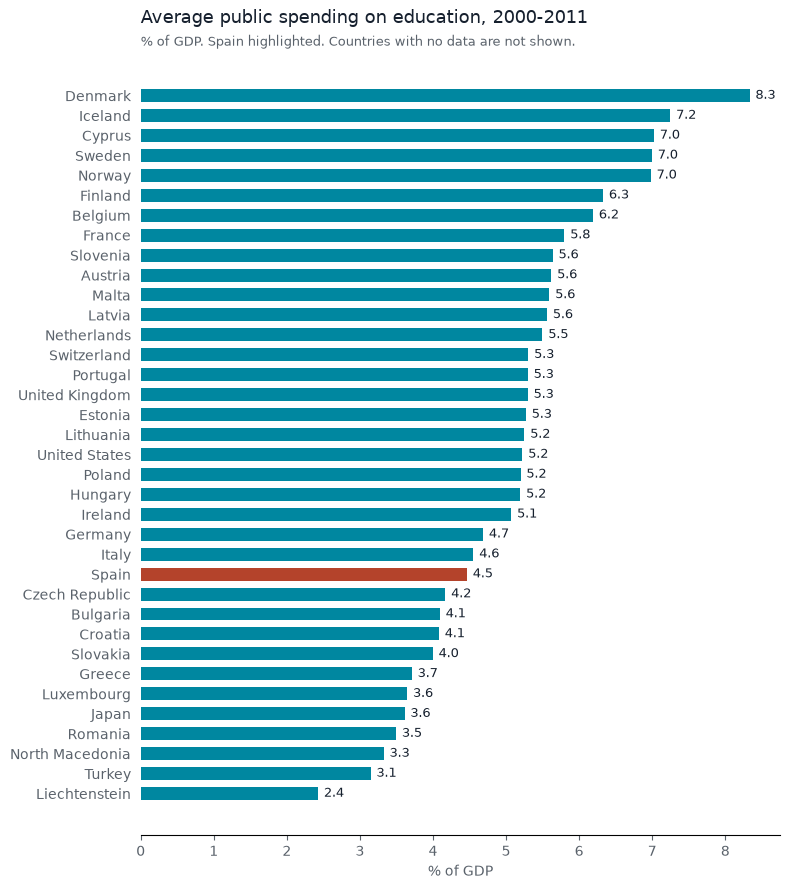

In [172]:
TEAL, TERRACOTTA, INK, MUTED = "#0087A0", "#B4432B", "#16202E", "#5A626B"

bars = means.dropna().sort_values()               # ascending, so the largest bar is drawn on top
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(bars.index, bars.values, height=0.65,
        color=[TERRACOTTA if c == "Spain" else TEAL for c in bars.index])
for y, v in enumerate(bars.values):
    ax.text(v + 0.08, y, f"{v:.1f}", va="center", fontsize=9, color=INK)

ax.set_title("Average public spending on education, 2000-2011", loc="left", fontsize=13, color=INK, pad=22)
ax.text(0, 1.01, "% of GDP. Spain highlighted. Countries with no data are not shown.",
        transform=ax.transAxes, fontsize=9, color=MUTED)
ax.set_xlabel("% of GDP", color=MUTED)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(left=False, colors=MUTED)
fig.tight_layout()
fig.savefig(OUTPUT / "mean_spending_by_country.png", dpi=150)
plt.show()

Now the **evolution over time**. A line chart needs few lines to stay readable: this function accepts at most 4 countries.

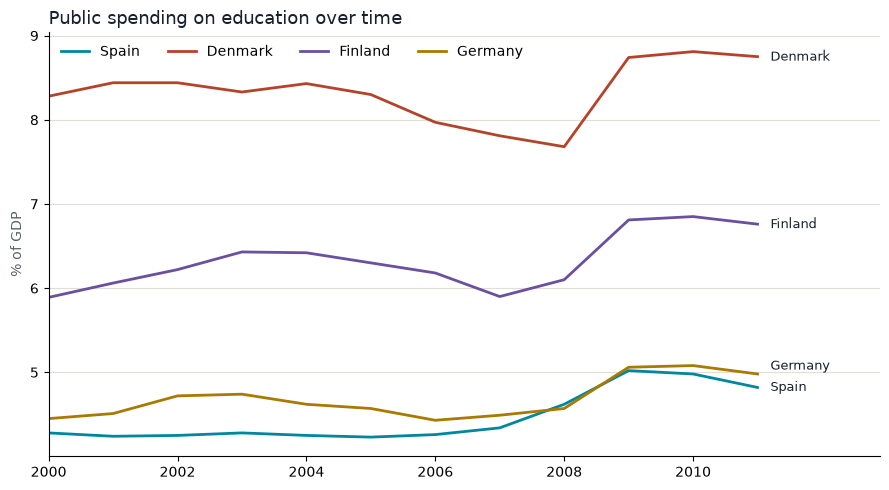

In [173]:
def plot_countries(selected):
    """Line chart of spending over time for up to 4 countries."""
    assert len(selected) <= 4, "More than 4 lines is hard to read: choose at most 4 countries"
    palette = ["#0087A0", "#B4432B", "#6B4FA0", "#A87A00"]
    series = period.pivot_table(values="value", index="year", columns="country")[selected]

    fig, ax = plt.subplots(figsize=(9, 5))
    for name, color in zip(selected, palette):
        ax.plot(series.index, series[name], color=color, linewidth=2, label=name)

    # Direct labels at the end of each line, nudged apart so they do not overlap
    ends = sorted((series[n].dropna().iloc[-1], n) for n in selected)
    y_prev = -99
    for value, name in ends:
        y = max(value, y_prev + 0.25)
        ax.text(2011.2, y, name, va="center", fontsize=9, color=INK)
        y_prev = y

    ax.set_xlim(2000, 2012.9)
    ax.set_xticks(range(2000, 2012, 2))
    ax.set_title("Public spending on education over time", loc="left", fontsize=13, color=INK)
    ax.set_ylabel("% of GDP", color=MUTED)
    ax.grid(axis="y", color="#E2DED3", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", ncol=len(selected))
    fig.tight_layout()
    plt.show()
    return fig


fig = plot_countries(["Spain", "Denmark", "Finland", "Germany"])
fig.savefig(OUTPUT / "spending_over_time.png", dpi=150)

### Your turn 4.2

Change the list below to **four countries of your choice** and run the cell. (To see the valid names: `sorted(period["country"].unique())`.) What stories do you see? Any surprise around 2009?

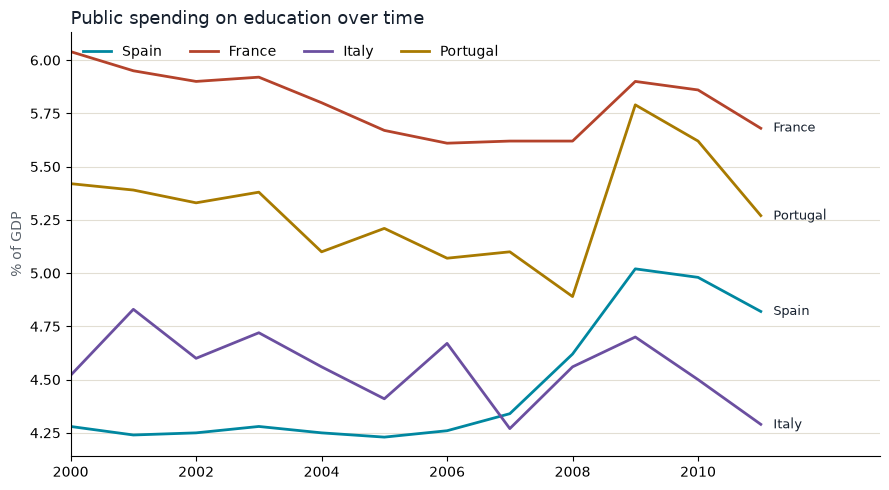

In [174]:
my_countries = ["Spain", "France", "Italy", "Portugal"]        # <-- change these
_ = plot_countries(my_countries)

### 4.3 The whole ETL in one command

The helper package runs **Extract → Transform → Load** from scratch, including the quality checks. Same code, one line:

In [175]:
from etl.pipeline import run

result = run()
print("Identical to our step-by-step result:", result.equals(final))

Extract : 41 rows x 22 columns (wide)
Transform: 444 rows, 46 missing values left as missing
Load    : education_spending.csv, education_spending.parquet, education_spending.db | round trip OK: True
Identical to our step-by-step result: True


You can also run it from a terminal with `uv run python -m etl.pipeline`. If someone else can run your pipeline and get the same result, the result can be **trusted**: that is **reproducibility**.

### Checkpoint: Load

- Which files have appeared in `data/processed/` and `output/`?
- Could a colleague repeat your analysis using only this project folder? What would they need?
- If Eurostat updated the data tomorrow, what would you have to change? (If the pipeline is well built: nothing.)

## Part 5 · Reflection

**1. Look back at your predictions** (the paper from Part 0).

- How many values did you predict were missing? In the TSV, 217 cells are `:` out of 861 (many are early years). For our period and real countries only, there are 46 missing values out of 444.
- Which country did you think spends the most? What do the data say? (Denmark. Check `means.head(1)`.)
- Did the file look like what you imagined?

**2. Discuss with your neighbour**

- What was the hardest decision in Transform? Did you and your neighbour decide the same?
- Which step would you not have thought of without the notebook?
- Which result would you not trust without checking it? How did you check?

**3. Self-assessment** (score 1 to 4)

1. I can explain what a DataFrame is.
2. I can explain what happens in Extract, Transform and Load.
3. I can say which decisions I took and why.
4. I know how to check a result.
5. I know what I would do if a dataset had planted errors like the one today.

**Going further**

- Run the same steps with another Eurostat dataset: `download_eurostat("<code>", DOWNLOADS)`.
- Do the **Part 6** hands-on exercises (films and ratings) on a new dataset.
- Repeat a few steps in polars (Appendix A).
- Open `etl/` and read the helper code. Can you change the period in `run(first_year=..., last_year=...)`?

## Part 6 · Hands on: films and ratings (extra practice)

*Optional: homework, or for pairs who finish early. About 45 minutes.*

Now you will use what you learned on a **different dataset**, with the questions of the original exercise sheet. **MovieLens 1M** contains about **one million ratings** (1 to 5 stars) given by 6,040 users to about 3,900 films.

It is the same ETL story:

| Phase | In this part |
|---|---|
| **Extract** | Read three text files with an unusual separator |
| **Transform** | Join the three tables, filter, group, pivot, sort |
| **Load** | Answer questions with a clear, checked result |

### How each exercise works

Every question is split into **small steps**. For each step you get:

1. **The idea** in plain words.
2. **A recipe**: a tiny example with a few rows you can read at a glance.
3. **Your turn**: replace `None` with your code, run the cell.
4. **Two hints** if you are stuck: the first gives the idea, the second is almost the answer.
5. **A check** cell that says `[OK]` or gives a hint.

You do **not** need to memorise any function. Copy the pattern from the recipe and change the names.

### 6.0 Extract: get the three files

The notebook looks for the data in `data/downloads/ml-1m/`. If it is not there, it tries to download it (about 6 MB). If you have no internet, your instructor will give you the folder: unzip it into `data/downloads/` so that `data/downloads/ml-1m/ratings.dat` exists.

In [176]:
from etl.movielens import find_movielens, download_movielens, read_movielens

ML_FOLDER = find_movielens(DOWNLOADS)
if ML_FOLDER is None:
    try:
        print("Downloading MovieLens 1M (about 6 MB)...")
        ML_FOLDER = download_movielens(DOWNLOADS)
        print("Done.")
    except RuntimeError as err:
        print("Download failed:", err)
        print("Ask your instructor for the folder 'ml-1m' and put it in data/downloads/")
else:
    print("Found the data in", ML_FOLDER)


def safe(test):
    """Run a check; if your answer is not ready yet, say False instead of showing an error."""
    try:
        return bool(test())
    except Exception:
        return False

Found the data in c:\Users\guill\Estudios\Master\Master_FPoDS\Agile Data Science\Agile\03-ETL_Material\etl-class-notebook-students\data\downloads\ml-1m


Three tables, three files. Look at how they are read: this is a good example of **why Extract needs care**.

- The fields are separated by **two colons** `::`, not by a comma. We tell pandas with `sep="::"` (and `engine="python"`, which is needed for a separator with two characters).
- The files have **no header row**, so we give the column names ourselves with `names=[...]` and `header=None`.
- Film titles contain accents (é, ñ…), so `movies.dat` is read with `encoding="latin-1"`.

All of that is already written in a helper function.

In [177]:
if ML_FOLDER is None:
    raise FileNotFoundError("MovieLens data not found: see the instructions in step 6.0")

users, ratings, movies = read_movielens(ML_FOLDER)

print("users  :", users.shape,   "(one row per person)")
print("ratings:", ratings.shape, "(one row per rating)")
print("movies :", movies.shape,  "(one row per film)")
ratings.head()

users  : (6040, 5) (one row per person)
ratings: (1000209, 4) (one row per rating)
movies : (3883, 3) (one row per film)


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


In [178]:
users.head()

,user_id,gender,age,occupation,zip
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


In [179]:
movies.head()

,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


**Look before you continue.** Which table says *who* rated? Which one says *what* film? Which one has the **gender**? Which one has the **title**?

The rating alone (`user_id`, `movie_id`, `rating`) does not tell us the title or the gender. To answer questions such as *"which films do women like more than men?"* we need **one table with everything**. That is a **merge** (also called a join).

### 6.1 Transform: merge the three tables

**The idea.** Two tables share a column (here `user_id`). `pd.merge(a, b)` puts them side by side, matching the rows that have the same `user_id`. By default pandas finds the shared column by itself.

**The recipe**, with tiny tables:

In [180]:
mini_ratings = pd.DataFrame({"user_id": [1, 1, 2],
                             "movie_id": [10, 20, 10],
                             "rating": [5, 3, 4]})
mini_users   = pd.DataFrame({"user_id": [1, 2], "gender": ["F", "M"]})
mini_movies  = pd.DataFrame({"movie_id": [10, 20], "title": ["Alien", "Brazil"]})

step1 = pd.merge(mini_ratings, mini_users)     # adds the gender, matching on user_id
step1

,user_id,movie_id,rating,gender
0,1,10,5,F
1,1,20,3,F
2,2,10,4,M


In [181]:
pd.merge(step1, mini_movies)                   # adds the title, matching on movie_id

,user_id,movie_id,rating,gender,title
0,1,10,5,F,Alien
1,1,20,3,F,Brazil
2,2,10,4,M,Alien


### Your turn 6.1

Merge the real tables: first `ratings` with `users`, then the result with `movies`. Store the result in `data`.

<details><summary>Hint 1 (the idea)</summary>

It is the recipe above, but with the real tables. You need two `pd.merge` calls, one inside the other, or one after the other.
</details>

<details><summary>Hint 2 (almost the answer)</summary>

`data = pd.merge(pd.merge(ratings, users), movies)`
</details>

In [182]:
# Replace None with your code
data = None

In [183]:
check("Exercise 6.1",
      safe(lambda: len(data) == len(ratings)
           and {"title", "gender", "rating"} <= set(data.columns)
           and data["title"].notnull().all()),
      "after merging, `data` must have as many rows as `ratings` and the columns title, gender and rating")
data.head() if data is not None else None

[not yet] Exercise 6.1. Hint: after merging, `data` must have as many rows as `ratings` and the columns title, gender and rating


Every row of `data` is now **one rating**, with who gave it (gender, age…) and for which film (title, genres).

### The toolbox for the next questions

Five patterns are enough for the whole sheet. Study them on this small table of 10 ratings (**read the output before moving on**).

In [184]:
mini = pd.DataFrame({
    "user_id": [1, 1, 1, 2, 2, 3, 3, 3, 4, 4],
    "gender":  ["F", "F", "F", "M", "M", "F", "F", "F", "M", "M"],
    "title":   ["Alien", "Brazil", "Casablanca", "Alien", "Brazil",
                "Alien", "Brazil", "Casablanca", "Alien", "Dune"],
    "rating":  [5, 3, 4, 4, 1, 5, 4, 4, 3, 5],
})
mini

,user_id,gender,title,rating
0,1,F,Alien,5
1,1,F,Brazil,3
2,1,F,Casablanca,4
3,2,M,Alien,4
4,2,M,Brazil,1
5,3,F,Alien,5
6,3,F,Brazil,4
7,3,F,Casablanca,4
8,4,M,Alien,3
9,4,M,Dune,5


**Pattern A · count the rows of each group.**

In [185]:
counts = mini.groupby("title").size()      # "for each title, how many rows?"
counts

title
Alien         4
Brazil        3
Casablanca    2
Dune          1
dtype: int64

**Pattern B · pick the labels that satisfy a condition.** `counts >= 3` gives True/False for each title; using it inside `counts.index[...]` keeps the titles that are True.

In [186]:
frequent = counts.index[counts >= 3]       # titles with at least 3 ratings
list(frequent)

['Alien', 'Brazil']

**Pattern C · keep the rows whose value is in a list** (`isin` means "is in").

In [187]:
mini_frequent = mini[mini["title"].isin(frequent)]
mini_frequent

,user_id,gender,title,rating
0,1,F,Alien,5
1,1,F,Brazil,3
3,2,M,Alien,4
4,2,M,Brazil,1
5,3,F,Alien,5
6,3,F,Brazil,4
8,4,M,Alien,3


**Pattern D · a table of averages, one row per film and one column per gender** (`pivot_table`). You say which column holds the **values**, which one gives the **rows**, which one gives the **columns**, and how to **combine** repeated values (here, the mean).

In [188]:
table = mini_frequent.pivot_table(values="rating", index="title", columns="gender", aggfunc="mean")
table

gender,F,M
title,,
Alien,5.00,3.50
Brazil,3.50,1.00


**Pattern E · sort and keep the first rows.** `ascending=False` puts the largest first; `head(n)` keeps the first `n`.

In [189]:
table.sort_values(by="F", ascending=False).head(2)

gender,F,M
title,,
Alien,5.00,3.50
Brazil,3.50,1.00


Two more tools, which you will meet later: a **new column from a calculation** (`table["diff"] = table["M"] - table["F"]`) and the **spread of the ratings** of a film (`groupby(...).std()`, the standard deviation: small when everybody agrees, large when opinions differ).

---

### Question 1 · Which films have at least 250 ratings?

**Why?** A film rated once by one person with 5 stars has a perfect average, but that average means nothing. We keep only films with enough ratings. This is the same kind of **decision** you took with missing values: write down your threshold.

**Recipe:** Pattern A, then B, then C.

### Your turn 6.2a · count the ratings of each film

Store in `ratings_per_title` the number of rows of `data` for each `title`.

<details><summary>Hint 1</summary>

Pattern A: `groupby("title").size()`, but on `data` instead of `mini`.
</details>

<details><summary>Hint 2</summary>

`ratings_per_title = data.groupby("title").size()`
</details>

In [190]:
ratings_per_title = None

In [191]:
check("Exercise 6.2a",
      safe(lambda: ratings_per_title.sum() == len(data) and ratings_per_title.index.is_unique),
      "you need one number per title, and all the numbers together must add up to the number of rows of `data`")

[not yet] Exercise 6.2a. Hint: you need one number per title, and all the numbers together must add up to the number of rows of `data`


### Your turn 6.2b · the titles with at least 250 ratings

Store in `active_titles` the titles whose count is **250 or more**.

<details><summary>Hint 1</summary>

Pattern B. The condition is "greater than or equal to": `>=`.
</details>

<details><summary>Hint 2</summary>

`active_titles = ratings_per_title.index[ratings_per_title >= 250]`
</details>

In [192]:
active_titles = None

In [193]:
check("Exercise 6.2b",
      safe(lambda: len(active_titles) > 0
           and (ratings_per_title[active_titles] >= 250).all()
           and len(active_titles) == (ratings_per_title >= 250).sum()),
      "all kept titles need 250 or more ratings, and no title with 250 or more may be missing")
print("Films kept:", len(active_titles) if active_titles is not None else "?")

[not yet] Exercise 6.2b. Hint: all kept titles need 250 or more ratings, and no title with 250 or more may be missing
Films kept: ?


### Your turn 6.2c · keep only the rating rows of those films

Store in `active` the rows of `data` whose `title` is in `active_titles`.

<details><summary>Hint 1</summary>

Pattern C: `data[data["title"].isin(...)]`.
</details>

<details><summary>Hint 2</summary>

`active = data[data["title"].isin(active_titles)]`
</details>

In [194]:
active = None

In [195]:
check("Exercise 6.2c",
      safe(lambda: set(active["title"]) == set(active_titles)
           and len(active) == ratings_per_title[active_titles].sum()),
      "`active` must contain every rating of the kept films, and nothing else")
print("Rows kept:", len(active) if active is not None else "?", "of", len(ratings))

[not yet] Exercise 6.2c. Hint: `active` must contain every rating of the kept films, and nothing else
Rows kept: ? of 1000209


**Think.** Many films disappeared and most ratings stayed. Why? (Ask your neighbour. Hint: are all films equally popular?)

---

### Question 2 · Mean rating of each film, by gender

**Recipe:** Pattern D, on `active`.

### Your turn 6.3

Store in `mean_ratings` a table with **one row per title** and **one column per gender** (`F` and `M`), containing the mean rating.

<details><summary>Hint 1</summary>

Pattern D: values = `"rating"`, index = `"title"`, columns = `"gender"`, aggfunc = `"mean"`.
</details>

<details><summary>Hint 2</summary>

`mean_ratings = active.pivot_table(values="rating", index="title", columns="gender", aggfunc="mean")`
</details>

In [196]:
mean_ratings = None

In [197]:
def _expected_means():
    """The same table, computed in a different way (grouping and then unstacking)."""
    return active.groupby(["title", "gender"])["rating"].mean().unstack()

check("Exercise 6.3",
      safe(lambda: set(mean_ratings.columns) == {"F", "M"}
           and set(mean_ratings.index) == set(active_titles)
           and np.allclose(mean_ratings[["F", "M"]].sort_index(), _expected_means()[["F", "M"]].sort_index())),
      "you need exactly two columns, F and M, one row per kept title, with the mean rating")
mean_ratings.head() if mean_ratings is not None else None

[not yet] Exercise 6.3. Hint: you need exactly two columns, F and M, one row per kept title, with the mean rating


---

### Question 3 · Which films do women rate highest?

**Recipe:** Pattern E.

### Your turn 6.4

Store in `top_women` the **10 films with the highest mean rating among women** (column `F`).

<details><summary>Hint 1</summary>

Sort `mean_ratings` by `"F"`, from the largest to the smallest, and keep the first 10.
</details>

<details><summary>Hint 2</summary>

`top_women = mean_ratings.sort_values(by="F", ascending=False).head(10)`
</details>

In [198]:
top_women = None

In [199]:
check("Exercise 6.4",
      safe(lambda: len(top_women) == 10
           and top_women["F"].iloc[0] == mean_ratings["F"].max()
           and top_women["F"].is_monotonic_decreasing),
      "10 rows, sorted from the highest F to the lowest")
top_women

[not yet] Exercise 6.4. Hint: 10 rows, sorted from the highest F to the lowest


---

### Question 4 · Where do men and women disagree?

We want three lists: films women like **more** than men, films men like **more** than women, and films with the most **discordant** ratings overall.

### Your turn 6.5a · the difference between men and women

Store in `diff` the **men's mean minus the women's mean** (`M` minus `F`) of every film. The next cell will add it to `mean_ratings` as a new column called `diff`.

- A **positive** `diff`: men rated it higher.
- A **negative** `diff`: women rated it higher.

<details><summary>Hint 1</summary>

A column of a table is a Series, and Series can be subtracted: `table["M"] - table["F"]` does the calculation for every film at once.
</details>

<details><summary>Hint 2</summary>

`diff = mean_ratings["M"] - mean_ratings["F"]`
</details>

In [200]:
diff = None        # replace None with the calculation

In [201]:
check("Exercise 6.5a",
      safe(lambda: np.allclose(diff, mean_ratings["M"] - mean_ratings["F"])),
      "diff = M - F, in that order: the sign matters")

# A new column is created by assigning to it
if diff is not None:
    mean_ratings["diff"] = diff

[not yet] Exercise 6.5a. Hint: diff = M - F, in that order: the sign matters


### Your turn 6.5b · films women like more than men

Store in `women_prefer` the **10 films with the most negative `diff`** (the biggest advantage for women).

<details><summary>Hint 1</summary>

Pattern E, sorted by `"diff"`. Women prefer = most negative = the **smallest** values first, so `ascending=True`.
</details>

<details><summary>Hint 2</summary>

`women_prefer = mean_ratings.sort_values(by="diff", ascending=True).head(10)`
</details>

In [202]:
women_prefer = None

In [203]:
check("Exercise 6.5b",
      safe(lambda: len(women_prefer) == 10 and women_prefer["diff"].iloc[0] == mean_ratings["diff"].min()),
      "the first row must have the smallest (most negative) diff")
women_prefer[["F", "M", "diff"]] if women_prefer is not None else None

[not yet] Exercise 6.5b. Hint: the first row must have the smallest (most negative) diff


### Your turn 6.5c · films men like more than women

Store in `men_prefer` the **10 films with the largest `diff`**. It is the same as 6.5b, but in the opposite direction.

<details><summary>Hint 1</summary>

Change `ascending=True` to `ascending=False`.
</details>

<details><summary>Hint 2</summary>

`men_prefer = mean_ratings.sort_values(by="diff", ascending=False).head(10)`
</details>

In [204]:
men_prefer = None

In [205]:
check("Exercise 6.5c",
      safe(lambda: len(men_prefer) == 10 and men_prefer["diff"].iloc[0] == mean_ratings["diff"].max()),
      "the first row must have the largest diff")
men_prefer[["F", "M", "diff"]] if men_prefer is not None else None

[not yet] Exercise 6.5c. Hint: the first row must have the largest diff


### Your turn 6.5d · the most discordant films, whatever the gender

A film is **discordant** if people disagree a lot about it. We measure it with the **standard deviation** of its ratings (large = opinions are spread out).

1. Store in `rating_std` the standard deviation of `rating` for each `title`, using only `active` (the films with enough ratings).
2. Store in `most_discordant` the 10 films with the **largest** standard deviation.

<details><summary>Hint 1</summary>

Pattern A, but with `["rating"].std()` instead of `.size()`, then Pattern E.
</details>

<details><summary>Hint 2</summary>

`rating_std = active.groupby("title")["rating"].std()` and
`most_discordant = rating_std.sort_values(ascending=False).head(10)`
</details>

In [206]:
rating_std = None
most_discordant = None

In [207]:
check("Exercise 6.5d",
      safe(lambda: set(rating_std.index) == set(active_titles)
           and len(most_discordant) == 10
           and most_discordant.iloc[0] == rating_std.max()),
      "one standard deviation per kept title; the first of the list is the largest")
most_discordant

[not yet] Exercise 6.5d. Hint: one standard deviation per kept title; the first of the list is the largest


**Think.** Do the films in `women_prefer` and `men_prefer` look like *different genres*? Could that be a **bias in the data** (who uses MovieLens?) rather than a difference between men and women?

---

### Question 5 · Average rating of each user, and the best film

### Your turn 6.6a · the mean rating of each user

Store in `mean_per_user` the mean `rating` given by each `user_id`.

<details><summary>Hint 1</summary>

Pattern A with `user_id` as the group and `["rating"].mean()`.
</details>

<details><summary>Hint 2</summary>

`mean_per_user = data.groupby("user_id")["rating"].mean()`
</details>

In [208]:
mean_per_user = None

In [209]:
check("Exercise 6.6a",
      safe(lambda: mean_per_user.index.is_unique
           and len(mean_per_user) == ratings["user_id"].nunique()
           and np.isclose(mean_per_user.loc[ratings["user_id"].iloc[0]],
                          ratings.loc[ratings["user_id"] == ratings["user_id"].iloc[0], "rating"].mean())),
      "one number per user; check one user by hand")
print("Most generous user gives on average:", round(mean_per_user.max(), 2) if mean_per_user is not None else "?")

[not yet] Exercise 6.6a. Hint: one number per user; check one user by hand
Most generous user gives on average: ?


### Your turn 6.6b · the film with the highest average rating (all films)

Store in `best_film_all` the **title** of the film with the highest mean rating, using **all** the data. Tip: `.idxmax()` returns the *label* of the largest value.

<details><summary>Hint 1</summary>

Mean rating of each title (like 6.6a, but grouping by title), then `.idxmax()`.
</details>

<details><summary>Hint 2</summary>

`best_film_all = data.groupby("title")["rating"].mean().idxmax()`
</details>

In [210]:
best_film_all = None

In [211]:
def _is_best(title, table):
    """Is `title` the film with the highest mean rating in `table`?"""
    means = table.groupby("title")["rating"].mean()
    return means[title] == means.max()

check("Exercise 6.6b",
      safe(lambda: _is_best(best_film_all, data)),
      "the film whose mean rating equals the maximum mean rating")
if best_film_all is not None:
    print(best_film_all, "->", (ratings["movie_id"].isin(movies.loc[movies["title"] == best_film_all, "movie_id"])).sum(), "ratings")

[not yet] Exercise 6.6b. Hint: the film whose mean rating equals the maximum mean rating


### Your turn 6.6c · the best film, among films with enough ratings

Do the same, but only with films that have 250 or more ratings (use `active`). Store the title in `best_film_active`.

<details><summary>Hint 1</summary>

Same as 6.6b, replacing `data` with `active`.
</details>

<details><summary>Hint 2</summary>

`best_film_active = active.groupby("title")["rating"].mean().idxmax()`
</details>

In [212]:
best_film_active = None

In [213]:
check("Exercise 6.6c",
      safe(lambda: _is_best(best_film_active, active)),
      "like 6.6b, but starting from `active`")
if best_film_active is not None:
    print(best_film_active, "->", (ratings["movie_id"].isin(movies.loc[movies["title"] == best_film_active, "movie_id"])).sum(), "ratings")

[not yet] Exercise 6.6c. Hint: like 6.6b, but starting from `active`


**Think.** Are the two answers the same? If not, which one would you put in a report, and why? (This is the same kind of decision as "what to do with missing values": same data, different rule, different conclusion.)

---

### Question 6 · A function: the favourite films of a user

**What is a function?** A recipe with a name. You give it an **input** and it **returns** a result. You write it once and reuse it with different inputs.

In [214]:
def double(x):          # "double" is the name, "x" is the input
    return 2 * x        # "return" is the result

print(double(4), double(10))

8 20


We want `top_movies(user)`: the films that this user rated highest. Let us build it in two steps, first for **one** user, then as a function.

### Your turn 6.7a · the ratings of user number 1

Store in `user_1` the rows of `data` where `user_id` is `1`.

<details><summary>Hint 1</summary>

Filter, like in Part 1: `data[data["user_id"] == 1]`. (Careful: two equal signs `==` to compare.)
</details>

<details><summary>Hint 2</summary>

`user_1 = data[data["user_id"] == 1]`
</details>

In [215]:
user_1 = None

In [216]:
check("Exercise 6.7a",
      safe(lambda: len(user_1) == (ratings["user_id"] == 1).sum() and (user_1["user_id"] == 1).all()),
      "only the rows of user 1, all of them")

[not yet] Exercise 6.7a. Hint: only the rows of user 1, all of them


### Your turn 6.7b · the 5 titles user 1 rated highest

Store in `top5_user_1` the **titles** of the 5 highest-rated films of `user_1`. Sort by `rating` from the highest, keep 5 rows, then take the `title` column.

<details><summary>Hint 1</summary>

Pattern E on `user_1`, sorting by `"rating"`; then select the `"title"` column.
</details>

<details><summary>Hint 2</summary>

`top5_user_1 = user_1.sort_values(by="rating", ascending=False).head(5)["title"]`
</details>

In [217]:
top5_user_1 = None

In [218]:
def _top_ok(user, result, n=5):
    """Are these really the user's n highest-rated films? (ties allowed)"""
    rows = data[data["user_id"] == user]
    threshold = rows["rating"].nlargest(n).min()
    chosen = rows[rows["title"].isin(list(result))]
    return len(list(result)) == n and len(chosen) == n and (chosen["rating"] >= threshold).all()

check("Exercise 6.7b", safe(lambda: _top_ok(1, top5_user_1)),
      "5 titles, each rated at least as high as the user's fifth best rating")

[not yet] Exercise 6.7b. Hint: 5 titles, each rated at least as high as the user's fifth best rating


### Your turn 6.7c · the function

Turn the two steps into a function `top_movies(user, n=5)` that returns the `n` best-rated **titles** of that user. Replace the user number `1` by the input `user`.

<details><summary>Hint 1</summary>

Copy your two lines into the function, and change `1` to `user` and `5` to `n`. The last line must start with `return`.
</details>

<details><summary>Hint 2</summary>

```python
def top_movies(user, n=5):
    rows = data[data["user_id"] == user]
    return rows.sort_values(by="rating", ascending=False).head(n)["title"]
```
</details>

In [219]:
def top_movies(user, n=5):
    # write your code here, ending with a line that starts with "return"
    return None

In [220]:
_some_users = [int(u) for u in ratings["user_id"].drop_duplicates().iloc[[0, 1, -1]]]
check("Exercise 6.7c",
      safe(lambda: all(_top_ok(u, top_movies(u)) for u in _some_users)
           and _top_ok(_some_users[0], top_movies(_some_users[0], n=3), n=3)),
      "it must work for any user and for any n; test it with top_movies(2) and top_movies(2, n=3)")

[not yet] Exercise 6.7c. Hint: it must work for any user and for any n; test it with top_movies(2) and top_movies(2, n=3)


In [221]:
top_movies(2)

---

### What you did, in ETL terms

- **Extract:** read three files with a strange separator, no header and accented text.
- **Transform:** merged three tables into one, filtered with a *decision* (at least 250 ratings), grouped, pivoted, sorted, built a function.
- **Load:** you produced answers and **checked** each one in a different way than you computed it.

**Discuss with your neighbour**

1. Which exercise would give a different answer if you changed 250 to 50? Try it.
2. In 6.6, which answer is the one you would trust? How would you justify your choice to a colleague?
3. What would you need to turn this exercise into a reusable pipeline like the one in Part 4?

## Appendix A · The same in polars (optional)

**polars** is a newer DataFrame library, usually faster and with a more explicit style. The ideas are the same; the syntax changes.

| Idea | pandas | polars |
|---|---|---|
| Read a CSV | `pd.read_csv(path, na_values=":")` | `pl.read_csv(path, null_values=":")` |
| Select a column | `df["Value"]` | `df.select("Value")` |
| Filter rows | `df[df["Value"] > 6.5]` | `df.filter(pl.col("Value") > 6.5)` |
| Group and mean | `df.groupby("GEO")["Value"].mean()` | `df.group_by("GEO").agg(pl.col("Value").mean())` |
| Sort | `df.sort_values("x", ascending=False)` | `df.sort("x", descending=True)` |

In [222]:
import polars as pl

edu_pl = pl.read_csv(RAW / "educ_figdp_1_Data.csv", null_values=":", columns=["TIME", "GEO", "Value"])

(edu_pl
   .group_by("GEO")
   .agg(pl.col("Value").mean().alias("mean_spending"))
   .sort("mean_spending", descending=True, nulls_last=True)
   .head(5))

GEO,mean_spending
str,f64
"""Denmark""",8.331667
"""Cyprus""",7.023333
"""Finland""",6.326667
"""Belgium""",6.189091
"""France""",5.7975


## Appendix B · Glossary

| Term | Meaning |
|---|---|
| **ETL** | Extract, Transform, Load: get data, clean it, leave it somewhere useful |
| **DataFrame** | A table whose columns have types and whose rows and columns have labels |
| **Series** | One column of a DataFrame |
| **Index** | The labels of the rows |
| **NaN** | "Not a number": a missing value. Not zero |
| **Flag** | A note attached to a data point ("estimated", "definition differs"…) |
| **Aggregate** | A group of countries (EU28) rather than a country |
| **Melt / unpivot** | From a wide table (one column per year) to a long one (one row per year) |
| **Pivot** | From a long table to a wide matrix |
| **Join / merge** | Matching two tables on a shared column |
| **Group by** | Split by categories, compute something on each part, recombine |
| **Parquet** | A compact column-based file format that keeps types |
| **SQLite** | A database stored in a single file |
| **Pivot table** | A table of summaries (for example means) with one row per category and one column per category |
| **Standard deviation** | How spread out values are: small if they agree, large if they differ |
| **Function** | A recipe with a name: it takes an input and returns a result |
| **Reproducibility** | Anyone can re-run the process and get the same result |